In [1]:
import scanpy as sc
import numpy as np 
import matplotlib.pyplot as plt
import pandas as pd
import scvelo as scv
import anndata as ad
import pickle as pkl
import seaborn as sns
import scipy.sparse as sp

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

from sklearn.decomposition import PCA
import umap
from itertools import product

python_data_dir = r"C:\Users\Nikla\Documents\MoBi_Master_FS.3\Internship AG Höfer\DynaVelo_testing\data"

## Load ATAC data and subset Peaks

In [ ]:
adata_atac_full = sc.read_h5ad(fr"{python_data_dir}\all_atac_peaks_corr.h5ad")  #corr for "corrected"
peak_type_annotation = pd.read_csv(rf"{python_data_dir}\Exp4_ctr_peak_types.csv", header=0, index_col=0)
peak_type_annotation = peak_type_annotation[peak_type_annotation["peak_id"].isin(adata_atac_full.var_names.values)]
print("All indices present:", (peak_type_annotation["peak_id"].isin(adata_atac_full.var_names.values)).all())
keep_peaks = peak_type_annotation.loc[peak_type_annotation["peakType"]=="Promoter"]  # left with roughly 27k peaks for promoters
keep_peaks 
adata_atac_full = adata_atac_full[:, adata_atac_full.var_names.isin(keep_peaks["peak_id"])]

## Load RNA data and subset to select HVGs

In [ ]:
adata_rna = sc.read_h5ad(rf"{python_data_dir}\all_rna_counts.h5ad")

nn_idx_path = rf"{python_data_dir}\nn_idx.txt"
nn_dist_path = rf"{python_data_dir}\nn_dist.txt"
nn_cells_path = rf"{python_data_dir}\nn_cells.txt"

nn_idx = np.loadtxt(str(nn_idx_path), delimiter=',')
nn_dist = np.loadtxt(str(nn_dist_path), delimiter=',')
nn_cells = pd.Index(pd.read_csv(str(nn_cells_path), header=None)[0])
nn_cells = nn_cells.str.replace('-1', '', regex=False)

shared_cells = pd.Index(np.intersect1d(adata_rna.obs_names, adata_atac_full.obs_names))
#shared_genes = pd.Index(np.intersect1d(adata_rna.var_names, adata_atac_full.var_names))
adata_rna.obs.rename(columns={"cell_type": "celltype"}, inplace=True)
adata_rna = adata_rna[shared_cells,:]
adata_atac_full = adata_atac_full[shared_cells,:]

embedding_genes = pd.read_csv(rf"C:\Users\Nikla\Documents\MoBi_Master_FS.3\Internship AG Höfer\DynaVelo_preprocessing\data\Exp4_ctr_rna_pca_genes.csv", header=[0]).T.values.tolist()[0]
adata_rna.var['highly_variable'] = adata_rna.var_names.isin(embedding_genes)

adata_rna = adata_rna[:,adata_rna.var['highly_variable']]  # Subset to the embedding genes only, use this to subset peaks

## Subset both RNA and ATAC to have common peaks/genes

In [ ]:
embedding_peaks = keep_peaks[keep_peaks["nearestGene"].isin(adata_rna.var_names.values)]
adata_atac_sub = adata_atac_full[:,embedding_peaks["peak_id"]]
atac_new_X = np.zeros(shape=adata_rna.shape)
(adata_rna.obs_names.values == adata_atac_sub.obs_names.values).all()  # indices are in the same order!

df = embedding_peaks[["peak_id", "nearestGene"]].drop_duplicates()

peak_idx = pd.Index(adata_atac_sub.var_names).get_indexer(df["peak_id"])
gene_idx = pd.Index(adata_rna.var_names).get_indexer(df["nearestGene"])

keep = (peak_idx >= 0) & (gene_idx >= 0)

M = sp.csr_matrix(
    (np.ones(keep.sum(), dtype=np.float32), (peak_idx[keep], gene_idx[keep])),
    shape=(adata_atac_sub.n_vars, adata_rna.n_vars),
)

atac_new_X = adata_atac_sub.X @ M
atac_new_X = atac_new_X.toarray()

adata_atac_pmtrs = ad.AnnData(X=atac_new_X)
adata_atac_pmtrs.var_names = adata_rna.var_names
adata_atac_pmtrs.obs_names = adata_rna.obs_names

In [ ]:
adata_atac_pmtrs.write_h5ad(rf"{python_data_dir}\pmtr_peak_sub\atac.h5ad")
adata_rna.write_h5ad(rf"{python_data_dir}\pmtr_peak_sub\rna.h5ad")

## Work with aligned data subsets
Begin by loading data...

In [2]:
adata_atac_all_lin = sc.read_h5ad(rf"{python_data_dir}\pmtr_peak_sub\atac.h5ad")
adata_rna_all_lin = sc.read_h5ad(rf"{python_data_dir}\pmtr_peak_sub\rna.h5ad")

In [3]:
adata_atac_all_lin.layers["counts"] = adata_atac_all_lin.X.copy()
sc.pp.normalize_total(adata_atac_all_lin, target_sum=np.median(adata_atac_all_lin.X.sum(1)))
sc.pp.log1p(adata_atac_all_lin)

In [4]:
sc.pp.pca(adata_rna_all_lin)

In [5]:
myeloid_cells = adata_rna_all_lin.obs_names.values[adata_rna_all_lin.obsm["X_pca"][:,1]<=1]  # filter to only myeloid lineage
adata_atac = adata_atac_all_lin[myeloid_cells,:]
adata_rna = adata_rna_all_lin[myeloid_cells,:]

In [6]:
X_pca = adata_rna.obsm["X_pca"]

In [7]:
atac_df = pd.DataFrame(data=adata_atac.X, index=adata_atac.obs_names.values, columns=adata_atac.var_names.values)
rna_df = pd.DataFrame(data=adata_rna.X.toarray(), index=adata_rna.obs_names.values, columns=adata_rna.var_names.values)

In [8]:
def minmax_cols(df):
    mn, mx = df.min(axis=0), df.max(axis=0)
    rng = (mx - mn).replace(0, np.nan)   # constant columns would divide by zero
    return ((df - mn) / rng).fillna(0)

atac_df = minmax_cols(atac_df)
rna_df = minmax_cols(rna_df)

### Calculate the smoothed curves, classify

In [9]:
def gaussian_smooth_on_grid(x, y, grid):
    sigma = 0.1 * (grid.max() - grid.min())
    x, y, grid = map(np.asarray, (x, y, grid))
    w = np.exp(-0.5 * ((grid[:, None] - x[None, :]) / sigma) ** 2)  # (n_grid, n_points)
    return ((w @ y) / w.sum(axis=1)).tolist()

def monotonic(x, eps=0.1):
    dx = np.diff(x)
    return np.all(dx >= -eps) or np.all(dx <= eps)

def monotonicity(y, min_range=0.05):
    y = np.asarray(y, float)
    rng = np.ptp(y)
    if np.isnan(y).any() or rng < min_range:
        return dict(reversal=np.nan, direction=0, ptp=rng)
    drawdown = np.max(np.maximum.accumulate(y) - y)   # largest fall after a peak (violates "increasing")
    drawup   = np.max(y - np.minimum.accumulate(y))   # largest rise after a trough (violates "decreasing")
    return dict(reversal=min(drawdown, drawup) / rng,
                direction=1 if drawdown < drawup else -1,
                ptp=rng)

def classify_shape(y, tol=0.1, min_range=0.05):
    m = monotonicity(y, min_range=min_range)
    if np.isnan(m["reversal"]):
        shape = "nan" if np.isnan(y).any() else "flat"
    elif m["reversal"] <= tol:
        shape = "up" if m["direction"] == 1 else "down"
    else:
        shape = "transient"
    return shape, m

In [ ]:
gridsize = 25
TOL = 0.1 
MIN_RANGE = 0.05

monotonic_genes = {}
non_monotonic_genes = {}
skipped_zero = []

grid = np.linspace(X_pca[:, 0].min(), X_pca[:, 0].max(), gridsize)

for i, gene_name in enumerate(rna_df.columns):
    if (atac_df.iloc[:, i] == 0).all() or (rna_df.iloc[:, i] == 0).all():
        skipped_zero.append(gene_name)
        continue

    smoothed_atac = np.asarray(gaussian_smooth_on_grid(X_pca[:, 0], atac_df.iloc[:, i], grid))
    smoothed_rna  = np.asarray(gaussian_smooth_on_grid(X_pca[:, 0], rna_df.iloc[:, i], grid))

    shape_r, m_r = classify_shape(smoothed_rna, TOL, MIN_RANGE)
    shape_a, m_a = classify_shape(smoothed_atac, TOL, MIN_RANGE)

    entry = {"smooth_rna": smoothed_rna,
             "smooth_atac": smoothed_atac,
             "rna_shape": shape_r, "atac_shape": shape_a,
             "rna_reversal": m_r["reversal"], "atac_reversal": m_a["reversal"],
             "rna_ptp": m_r["ptp"], "atac_ptp": m_a["ptp"]}

    if shape_r in ("up", "down") and shape_a in ("up", "down"):
        monotonic_genes[gene_name] = entry
    else:
        non_monotonic_genes[gene_name] = entry

print("Monotonic:", len(monotonic_genes))
print("Non-monotonic:", len(non_monotonic_genes))
print("Skipped (all zero):", len(skipped_zero))
assert len(monotonic_genes) + len(non_monotonic_genes) + len(skipped_zero) == rna_df.shape[1]

shapes = pd.DataFrame({g: (d["rna_shape"], d["atac_shape"])
                       for g, d in {**monotonic_genes, **non_monotonic_genes}.items()},
                      index=["rna_shape", "atac_shape"]).T
print(pd.crosstab(shapes.rna_shape, shapes.atac_shape))

Monotonic: 112
Non-monotonic: 500
Skipped (all zero): 64
atac_shape  down  flat  transient  up
rna_shape                            
down          37   143         17  14
flat           6   106         14  23
transient      3    61         12  24
up             2    81         10  59


Visualize the differnt combinations for RNA and ATAC curve shape:

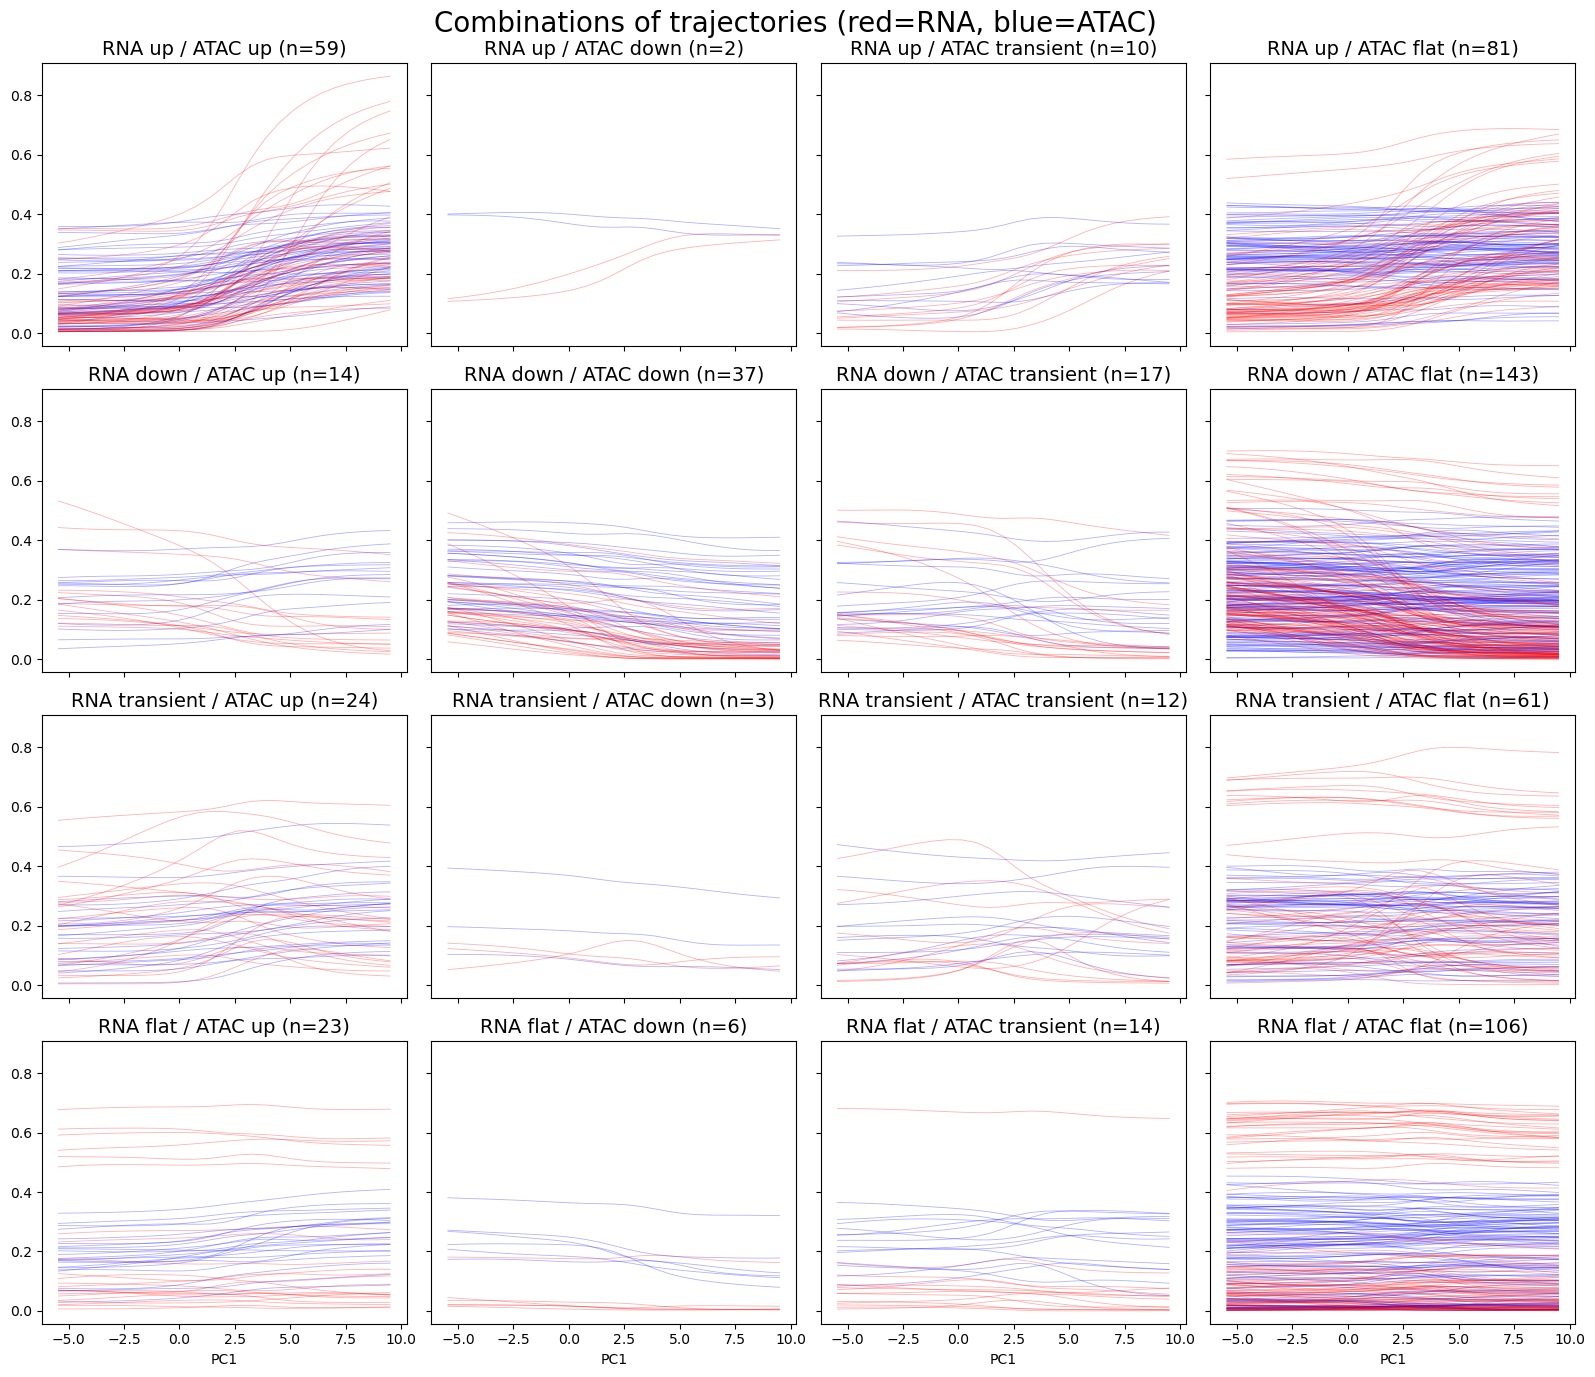

In [15]:
all_genes = {**monotonic_genes, **non_monotonic_genes}
shape_order = ["up", "down", "transient", "flat"]

fig, axs = plt.subplots(4, 4, figsize=(16, 14), sharex=True, sharey=True)

for i, rs in enumerate(shape_order):          # rows: RNA shape
    for j, a_s in enumerate(shape_order):     # columns: ATAC shape
        ax = axs[i, j]
        genes = [g for g, d in all_genes.items() if d["rna_shape"] == rs and d["atac_shape"] == a_s]
        for g in genes:
            ax.plot(grid, all_genes[g]["smooth_rna"],  color="red",  lw=0.6, alpha=0.3)
            ax.plot(grid, all_genes[g]["smooth_atac"], color="blue", lw=0.6, alpha=0.3)
        ax.set_title(f"RNA {rs} / ATAC {a_s} (n={len(genes)})", fontsize=14)

for ax in axs[-1]: ax.set_xlabel("PC1")
plt.suptitle("Combinations of trajectories (red=RNA, blue=ATAC)", fontsize=20)
plt.tight_layout()
plt.show()

Crucially, some of the curves look as through it would be best to remove the 0-count cells. However (!), here the importance of the ratio of count vs. 0-count cells becomes apparent, shaping the curve.

## Trying to identify clusters within the trajectories
First approach is to use only a few discriminant features, secondly we can try using the entire concatenated curves. First we define all the functions we will then apply to the monotonic, non-monotonic and all genes

In [15]:
def half_max_pos(y, grid):  # Finds the midpoint in the grid between the minimum and maximum
    y = (y - y.min()) / (y.max() - y.min())
    return grid[np.argmin(np.abs(y - 0.5))]

def curve_features(gene_dict, gridsize=25):

    t = (grid - grid.min()) / (grid.max() - grid.min())   # normalize time to 0-1
    rows = []

    for g, d in gene_dict.items():
        r, a = np.asarray(d["smooth_rna"]), np.asarray(d["smooth_atac"])

        rows.append(dict(gene=g,
                        monotonicity_r=monotonicity(r)["reversal"],
                        monotonicity_a=monotonicity(a)["reversal"],
                        rna_dir=np.sign(r[-1] - r[0]), 
                        atac_dir=np.sign(a[-1] - a[0]),
                        t_rna=half_max_pos(r, t), 
                        t_atac=half_max_pos(a, t),
                        # RNA
                        rna_max=np.max(r),
                        rna_max_idx=np.argmax(r)/gridsize,
                        rna_min=np.min(r),
                        rna_min_idx=np.argmin(r)/gridsize,
                        # ATAC
                        atac_max=np.max(a),
                        atac_max_idx=np.argmax(a)/gridsize,
                        atac_min=np.min(a),
                        atac_min_idx=np.argmin(a)/gridsize,
                        ))
        
    feat = pd.DataFrame(rows).set_index("gene")
    feat["lag"] = feat.t_atac - feat.t_rna
    feat["lag_dir"] = np.sign(feat["lag"]).astype(int)
    return feat

def get_curves(gene_dict, gridsize=25):
    curves = pd.DataFrame(
        {g: np.concatenate([d["smooth_rna"], d["smooth_atac"]]) for g, d in gene_dict.items()},
        index=[f"rna_{i}" for i in range(gridsize)] + [f"atac_{i}" for i in range(gridsize)],
    ).T
    return curves

def plot_curve_heatmap(feat_df, curves, n=25):
    n = len(grid)

    def mm(A):  # per-gene min-max, so each row spans 0-1
        return (A - A.min(1, keepdims=True)) / np.maximum(np.ptp(A, axis=1, keepdims=True), 1e-12)

    # order genes: by direction group, then by RNA half-max position
    order = feat_df.sort_values(["rna_dir", "atac_dir", "t_rna"]).index
    X = curves.loc[order].values
    R, A = mm(X[:, :n]), mm(X[:, n:])
    extent = [grid.min(), grid.max(), len(order), 0]

    fig, axs = plt.subplots(1, 3, figsize=(15, 6), sharey=True)
    axs[0].imshow(R, aspect="auto", cmap="viridis", extent=extent); axs[0].set_title("RNA")
    axs[1].imshow(A, aspect="auto", cmap="viridis", extent=extent); axs[1].set_title("ATAC")
    im = axs[2].imshow(A - R, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1, extent=extent)
    axs[2].set_title("ATAC - RNA"); plt.colorbar(im, ax=axs[2])
    
    for ax in axs: 
        ax.set_xlabel("PC1")
    
    axs[0].set_ylabel("genes")
    plt.tight_layout()
    plt.show()
    return

def plot_curve_clusters(feat_df):
    cols = ["t_rna", "t_atac", "lag", "rna_max", "atac_max", "rna_max_idx", "atac_max_idx", "rna_min", "atac_min",
            "rna_min_idx", "atac_min_idx"]

    Z = StandardScaler().fit_transform(feat_df[cols])
    feat_df["cluster"] = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Z)

    emb = umap.UMAP(n_neighbors=20, min_dist=0.1, random_state=0).fit_transform(Z)

    plt.scatter(emb[:, 0], emb[:, 1], c=feat_df["cluster"], cmap="viridis", s=10)
    plt.xlabel("UMAP1"); plt.ylabel("UMAP2")
    plt.show()
    return

def plot_curve_violinplots(feat_df, cols_plot=["rna_max_idx", "atac_max_idx"]):
    
    d = feat_df[feat_df["cluster"].isin([0, 1, 2])]

    ncol = 3
    nrow = int(np.ceil(len(cols_plot) / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(5 * ncol, 4 * nrow))

    for ax, c in zip(axs.ravel(), cols_plot):
        sns.violinplot(data=d, x="cluster", y=c, inner=None, cut=0, color="lightgray",
                    linewidth=0.8, density_norm="width", ax=ax)
        sns.stripplot(data=d, x="cluster", y=c, size=2, alpha=0.5, jitter=0.25,
                    color="black", ax=ax)
        ax.set_title(c)

    for ax in axs.ravel()[len(cols_plot):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
    return

## Monotonic Genes

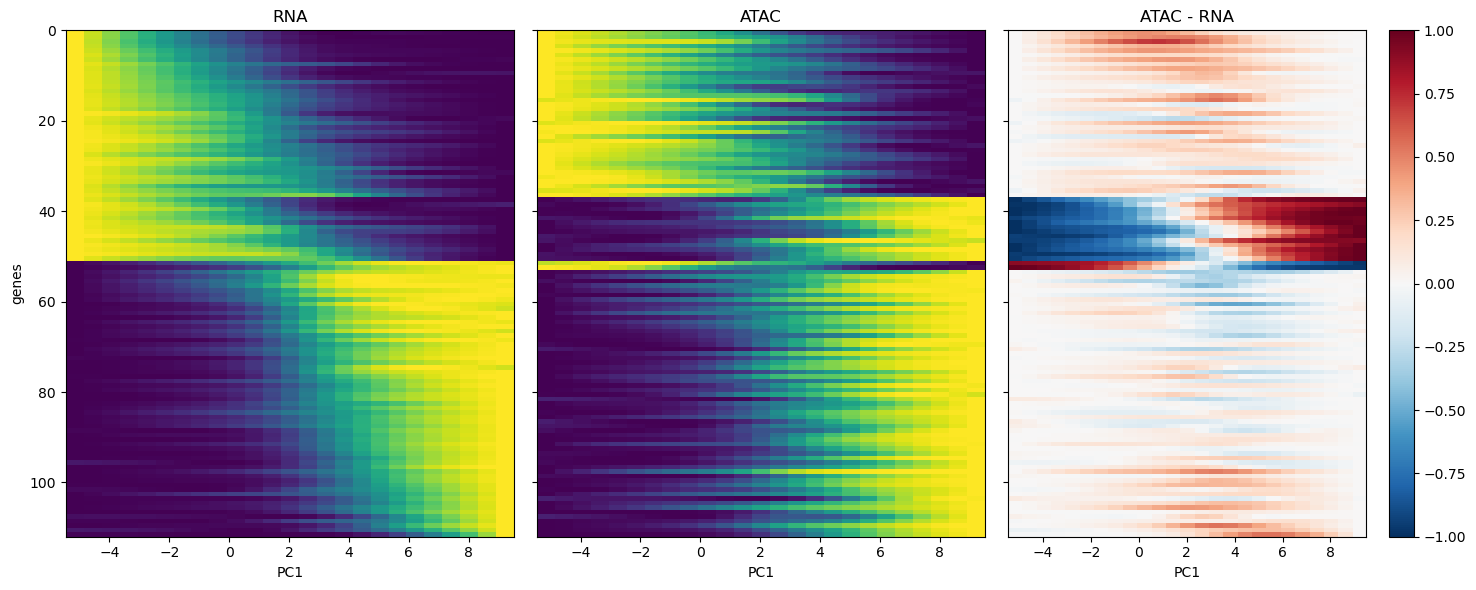

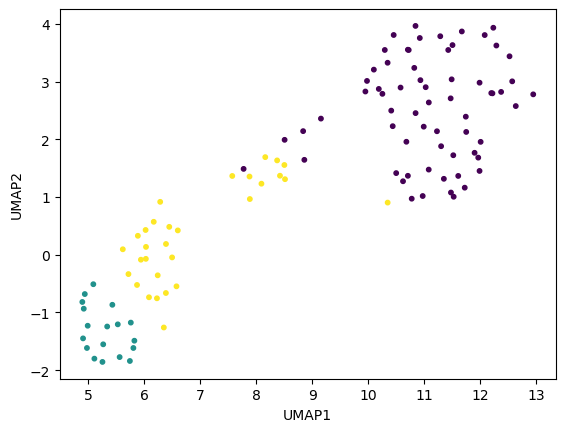

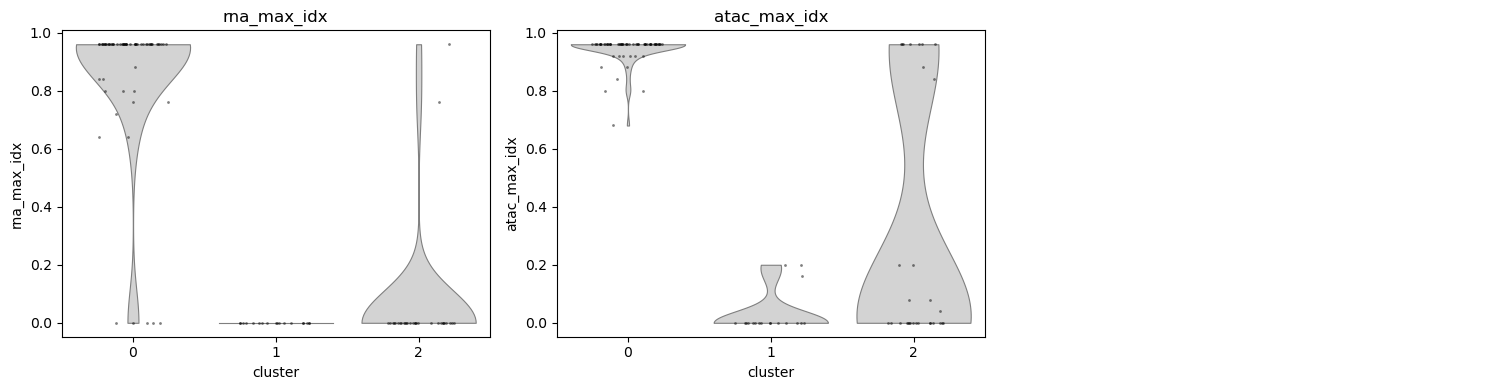

In [16]:
mono_feat = curve_features(monotonic_genes, gridsize)
mono_curves = get_curves(monotonic_genes, gridsize)

plot_curve_heatmap(mono_feat, mono_curves, n=gridsize)
plot_curve_clusters(mono_feat)
plot_curve_violinplots(mono_feat)

## Non-Monotonic Genes

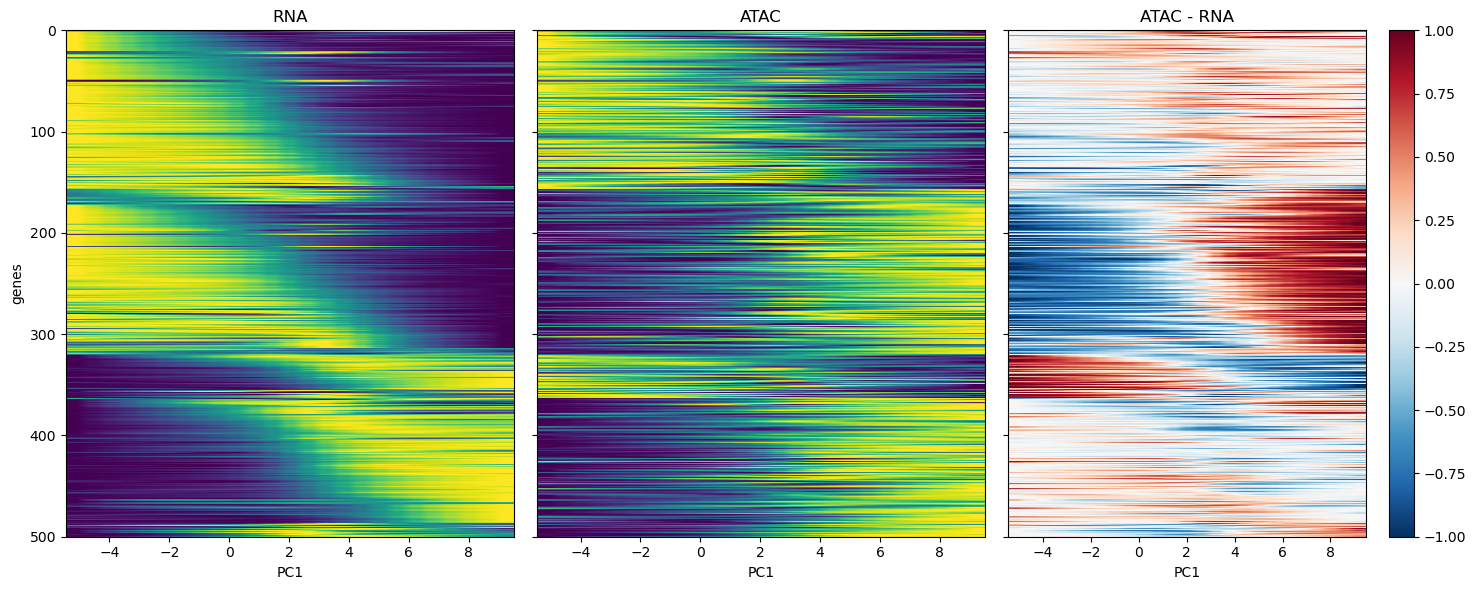

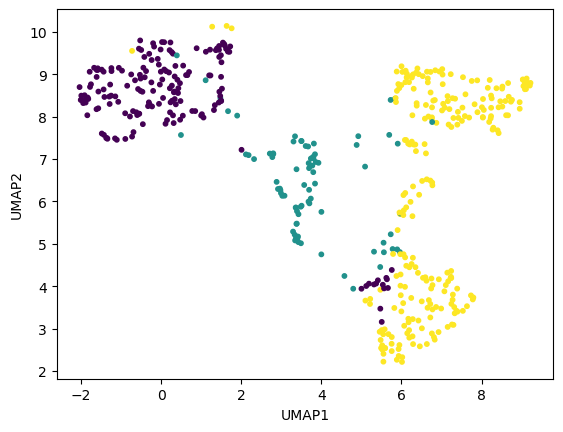

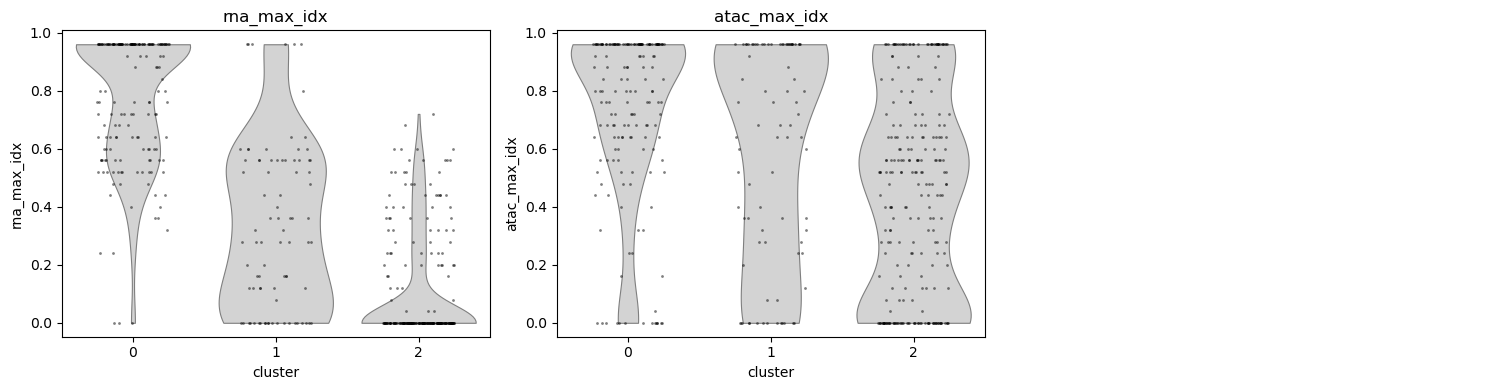

In [17]:
non_mono_feat = curve_features(non_monotonic_genes, gridsize)
non_mono_curves = get_curves(non_monotonic_genes, gridsize)

plot_curve_heatmap(non_mono_feat, non_mono_curves, n=gridsize)
plot_curve_clusters(non_mono_feat)
plot_curve_violinplots(non_mono_feat)

## All genes

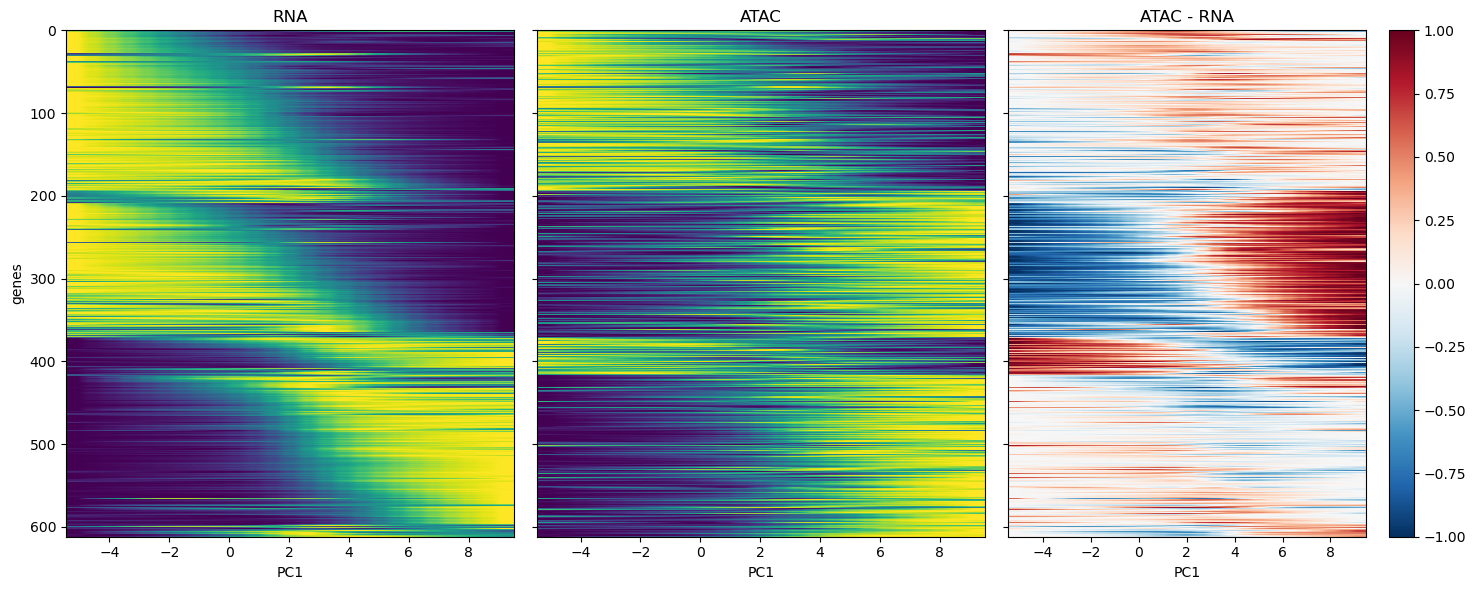

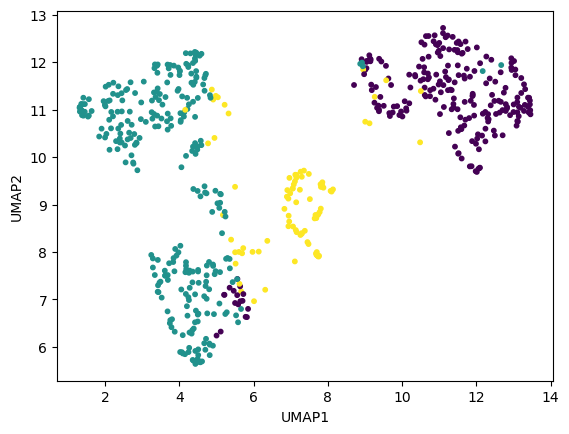

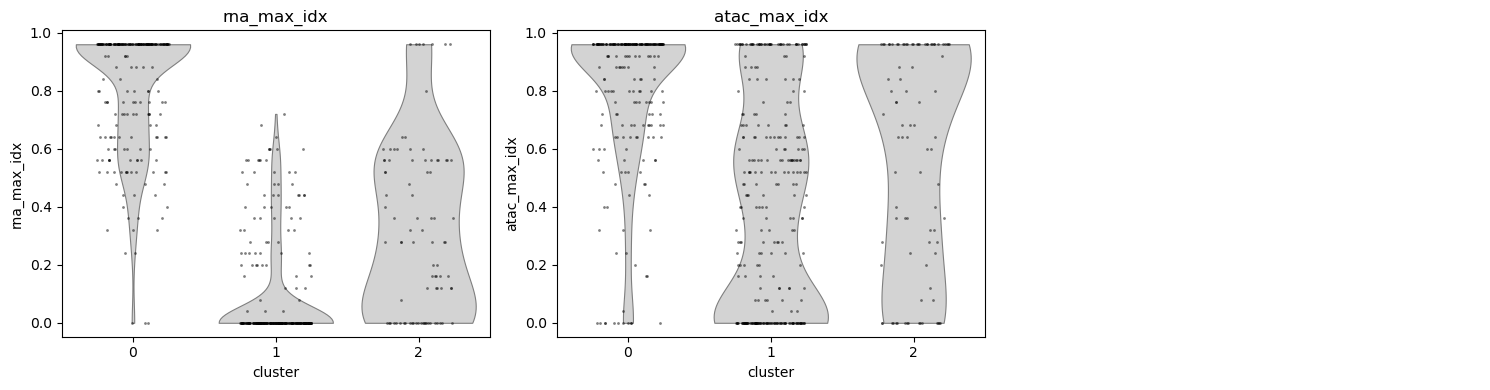

In [18]:
all_genes = monotonic_genes | non_monotonic_genes

all_feat = curve_features(all_genes, gridsize)
all_curves = get_curves(all_genes, gridsize)

plot_curve_heatmap(all_feat, all_curves, n=gridsize)
plot_curve_clusters(all_feat)
plot_curve_violinplots(all_feat)

## Analysis of pseudotime lag
We first carry this out for the monotonically increasing genes. However, this is not strictly required for the assumptions we are trying to check of chromatin velocity, where the RNA signal lags behind the ATAC signal.

In [53]:
lag_sorted_feats = mono_feat.sort_values(["lag"], ascending=False)
pca_data = adata_rna.obsm["X_pca"][:,:2]

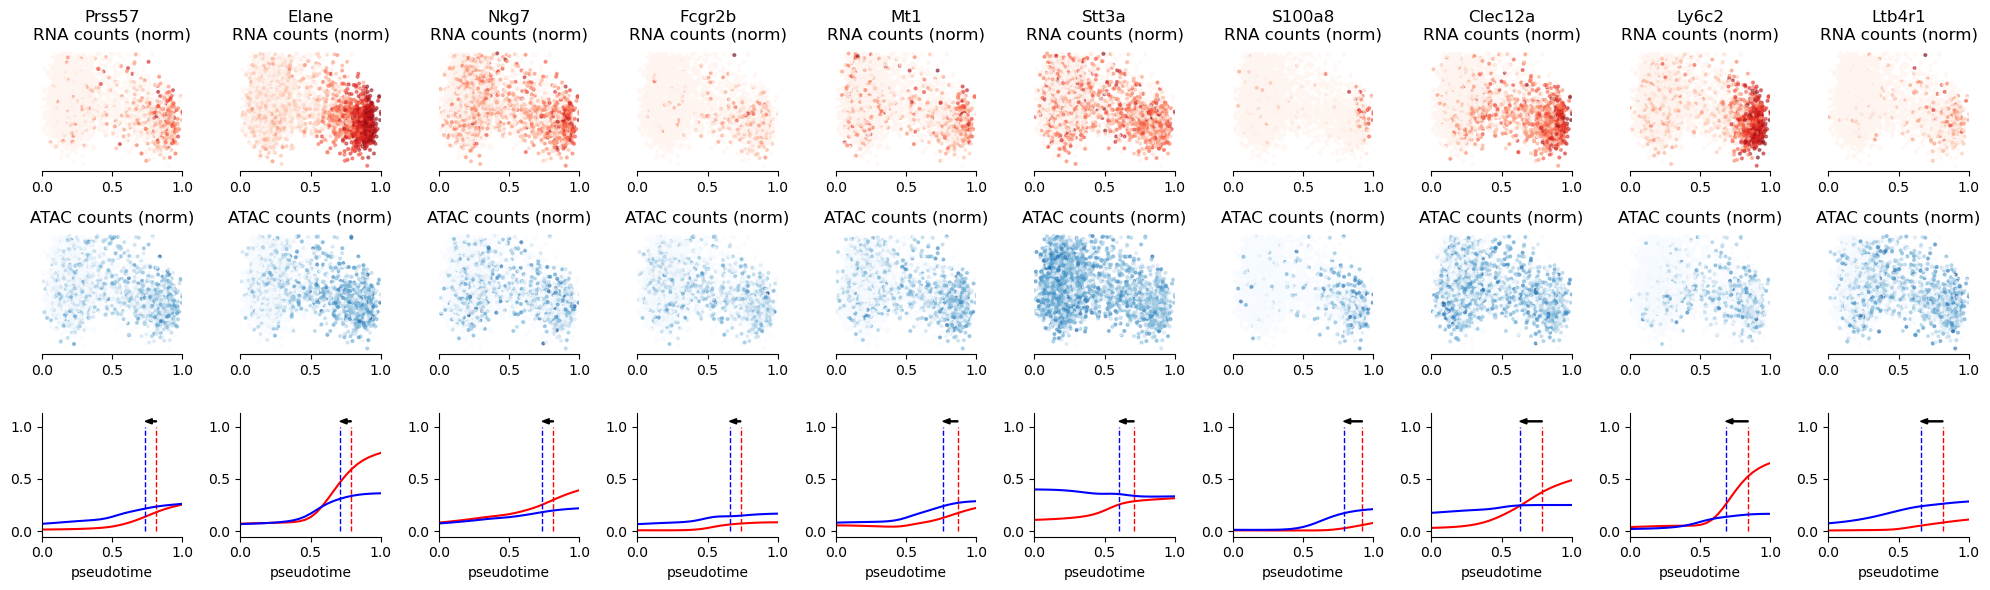

In [54]:
num_genes = 10

min_x = np.min(pca_data[:, 0])
max_x = np.max(pca_data[:, 0])
x_norm = (pca_data[:, 0] - min_x) / (max_x - min_x)

grid_norm = np.linspace(0, 1, 25)

fig, axs = plt.subplots(nrows=3, ncols=num_genes, figsize=(num_genes*2, 6))

for i, gene in enumerate(lag_sorted_feats.index.tolist()[-num_genes:]):

    axs[0, i].scatter(x_norm, pca_data[:, 1], c=adata_rna[:, gene].X.toarray(), cmap="Reds", s=4, alpha=0.5)
    axs[0, i].set_title(f"{gene}\nRNA counts (norm)", fontsize=12)

    axs[1, i].scatter(x_norm, pca_data[:, 1], c=adata_atac[:, gene].X.toarray(), cmap="Blues", s=4, alpha=0.5)
    axs[1, i].set_title("ATAC counts (norm)", fontsize=12)

    for r in (0, 1):
        axs[r, i].spines[['left', 'top', 'right']].set_visible(False)
        axs[r, i].get_yaxis().set_visible(False)

    curve_data = mono_curves.loc[gene, :].values

    t_rna = (mono_feat.loc[gene, "t_rna"] * max_x - min_x) / (max_x - min_x)
    t_atac = (mono_feat.loc[gene, "t_atac"] * max_x - min_x) / (max_x - min_x)

    axs[2, i].plot(grid_norm, curve_data[:25], c="red")
    axs[2, i].plot(grid_norm, curve_data[25:], c="blue")
    axs[2, i].vlines(t_rna, ymin=0, ymax=1, color="red", zorder=1, linestyle="dashed", linewidth=1)
    axs[2, i].vlines(t_atac, ymin=0, ymax=1, color="blue", zorder=2, linestyle="dashed", linewidth=1)
    axs[2, i].arrow(t_rna, 1.05, t_atac - t_rna, 0, zorder=0, width=0.01,
                    head_width=0.05, head_length=0.05,  
                    facecolor="black", length_includes_head=True)

    axs[2, i].spines[['top', 'right']].set_visible(False)

    for r in range(3):
        axs[r, i].set_xlim(0, 1)
    axs[2, i].set_xlabel("pseudotime")

plt.tight_layout()
plt.show()

## Chromatin Velocity
Clearly some of the genes follow the expected behavior that is assumed by chromatin velocity. We subset to this set of genes and then compute our velocities.

In [29]:
# Load z-score data and compute correlations with aggregated peak data
z_scores = sc.read_h5ad(rf"{python_data_dir}\z_scores_raw.h5ad")
z_scores.obs_names = [i[9:-2] for i in z_scores.obs_names.values]
z_scores = z_scores[z_scores.obs_names.isin(rna_df.index.values),:]
z_scores = pd.DataFrame(z_scores.X, index=z_scores.obs_names.values, columns=z_scores.var_names.values)

z_scores = minmax_cols(z_scores)
mono_atac_curves = mono_curves.iloc[mono_curves.index.isin(list(monotonic_genes.keys())), gridsize:]
z_score_curves = pd.DataFrame(np.zeros(shape=(len(z_scores.T), gridsize)), index=z_scores.columns, columns=[f"z_{i}" for i in range(gridsize)])
assert (rna_df.index.values == z_scores.index.values).all()

In [30]:
skipped_zero = []

for gene in z_score_curves.index.values: 
    
    if (z_scores.loc[:,gene] == 0).all():
        skipped_zero.append(gene)
        continue
    
    z_score_curves.loc[gene,:] = np.asarray(gaussian_smooth_on_grid(X_pca[:, 0], z_scores.loc[:,gene], grid))

In [31]:
z_score_curves.to_csv(rf"{python_data_dir}\pmtr_peak_sub\z_score_curves.csv", index=True, header=True)
mono_atac_curves.to_csv(rf"{python_data_dir}\pmtr_peak_sub\mono_atac_curves.csv", index=True, header=True)

In [32]:
A = mono_atac_curves.values   # (n_atac_genes, n_points)
Z = z_score_curves.values     # (n_z_genes, n_points)

# Standardize each row (mean 0, std 1)
A_std = (A - A.mean(axis=1, keepdims=True)) / A.std(axis=1, keepdims=True)
Z_std = (Z - Z.mean(axis=1, keepdims=True)) / Z.std(axis=1, keepdims=True)

# Pearson r for every (atac gene, z gene) pair
corrs = pd.DataFrame(
    A_std @ Z_std.T / A.shape[1],
    index=mono_atac_curves.index,
    columns=z_score_curves.index,
)

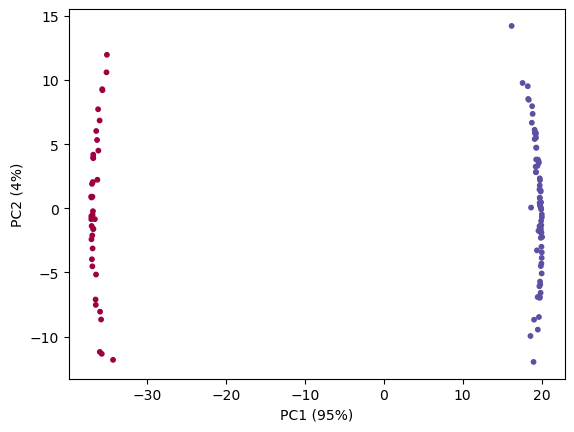

<Axes: >

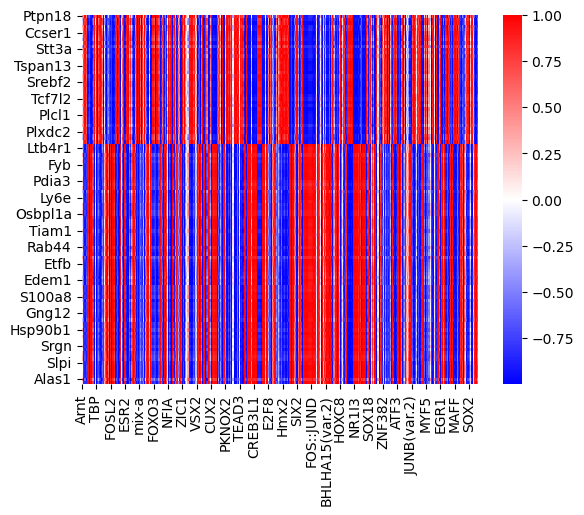

In [33]:
Z = StandardScaler().fit_transform(corrs)
clusters = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(Z)

P = PCA(n_components=2).fit(Z)
emb = P.transform(Z)

plt.scatter(emb[:, 0], emb[:, 1], c=clusters, cmap="Spectral", s=10)
plt.xlabel(f"PC1 ({P.explained_variance_ratio_[0]:.0%})")
plt.ylabel(f"PC2 ({P.explained_variance_ratio_[1]:.0%})")
plt.show()

corrs["clusters"] = clusters
order = corrs["clusters"].sort_values().index
corrs_sorted=corrs.loc[order]

sns.heatmap(corrs_sorted, cmap="bwr")

(array([ 3.,  1.,  2.,  0.,  5.,  8., 18.,  0., 14., 14., 14.,  0.,  7.,
         9., 10.,  0.,  5.,  0.,  1.,  1.]),
 array([-2.5000000000e-01, -2.1875000000e-01, -1.8750000000e-01,
        -1.5625000000e-01, -1.2500000000e-01, -9.3750000000e-02,
        -6.2500000000e-02, -3.1250000000e-02, -5.5511151231e-17,
         3.1250000000e-02,  6.2500000000e-02,  9.3750000000e-02,
         1.2500000000e-01,  1.5625000000e-01,  1.8750000000e-01,
         2.1875000000e-01,  2.5000000000e-01,  2.8125000000e-01,
         3.1250000000e-01,  3.4375000000e-01,  3.7500000000e-01]),
 <BarContainer object of 20 artists>)

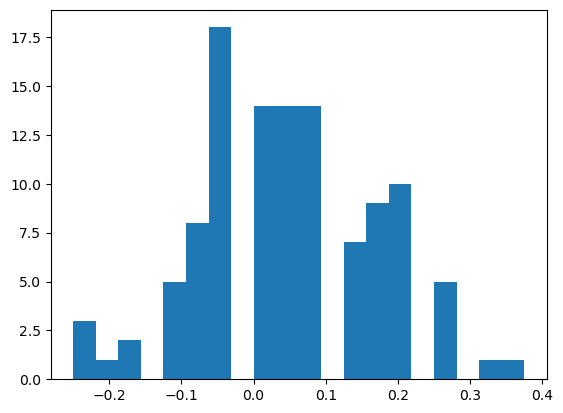

In [58]:
plt.hist(lag_sorted_feats["lag"], bins=20)

Cluster 0 is atac down, cluster 1 is atac up. Their correlation is more just an assignment if the motifs are monotonically increasing or decreasing. Overall, all the remaining genes show a strong correlation with at least one motif. Finally, I want to filter out all the genes, where there is a lag between RNA and ATAC, with the ATAC signal preceding the RNA signal. Further also RNA and ATAC should be either monotonically increasing or decreasing. The direction of the lag is the same for both cases, with the ATAC signal decreasing at an earlier pseudotime as the RNA signal.

In [57]:
lag_subset_feats = lag_sorted_feats[(lag_sorted_feats["rna_dir"] == lag_sorted_feats["atac_dir"])]# & (lag_sorted_feats["lag"] < 0)]
lag_subset_feats.to_csv(rf"{python_data_dir}\pmtr_peak_sub\chrom_velo_gene_subset.csv", index=True)

I believe that precisely because the direction of lag is correct for both increasing and decreasing genes, this makes the entire selection process independent of any prior knowledge about the pseudotime

## Testing branching

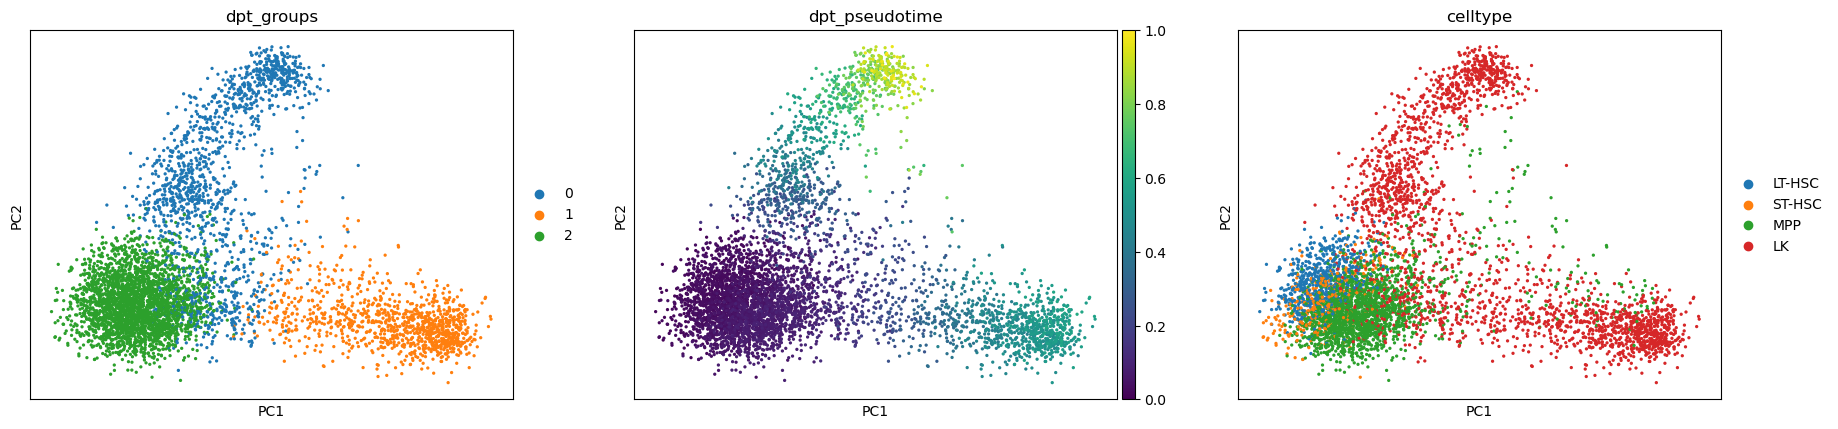

In [40]:
ad_t = adata_rna_all_lin.copy()          # all cells, both branches

# joint embedding (modality-neutral axis for pseudotime)
assert (adata_atac_all_lin.obs_names == ad_t.obs_names).all()
sc.pp.pca(adata_atac_all_lin, n_comps=30)
rna_pc = ad_t.obsm["X_pca"][:, :30]
atac_pc = adata_atac_all_lin.obsm["X_pca"][:, :30]
ad_t.obsm["X_joint"] = np.hstack([rna_pc / rna_pc.std(), atac_pc / atac_pc.std()])

sc.pp.neighbors(ad_t, n_neighbors=30, use_rep="X_joint")
sc.tl.diffmap(ad_t)

# root: cell closest to the centroid of the LT-HSC population in diffusion space
dm = ad_t.obsm["X_diffmap"]
root_mask = (ad_t.obs["celltype"] == "LT-HSC").values
ad_t.uns["iroot"] = int(np.argmin(np.linalg.norm(dm - dm[root_mask].mean(0), axis=1)))

sc.tl.dpt(ad_t, n_branchings=1)          # adds dpt_pseudotime and dpt_groups
sc.pl.pca(ad_t, color=["dpt_groups", "dpt_pseudotime", "celltype"])

In [55]:
atac_all = pd.DataFrame(adata_atac_all_lin.X, index=adata_atac_all_lin.obs_names,
                        columns=adata_atac_all_lin.var_names)
rna_all  = pd.DataFrame(adata_rna_all_lin.X.toarray(), index=adata_rna_all_lin.obs_names,
                        columns=adata_rna_all_lin.var_names)

pt = ad_t.obs["dpt_pseudotime"]
branch_subsets = {}

for k in ["1", "2"]:
    cells  = ad_t.obs_names[ad_t.obs["dpt_groups"].isin(["0", k])]
    x      = pt.loc[cells].values
    rna_b  = minmax_cols(rna_all.loc[cells])      # rescale within the branch
    atac_b = minmax_cols(atac_all.loc[cells])

    grid = np.linspace(x.min(), x.max(), gridsize)   # curve_features reads this global
    mono = {}
    for g in rna_b.columns:
        if (atac_b[g] == 0).all() or (rna_b[g] == 0).all():
            continue
        sr = np.asarray(gaussian_smooth_on_grid(x, rna_b[g], grid))
        sa = np.asarray(gaussian_smooth_on_grid(x, atac_b[g], grid))
        shape_r, _ = classify_shape(sr, TOL, MIN_RANGE)
        shape_a, _ = classify_shape(sa, TOL, MIN_RANGE)
        if shape_r in ("up", "down") and shape_a in ("up", "down"):
            mono[g] = {"smooth_rna": sr, "smooth_atac": sa}

    feat = curve_features(mono, gridsize)
    branch_subsets[k] = feat[(feat["lag"] < 0) & (feat["rna_dir"] == feat["atac_dir"])]
    print(k, len(mono), "monotonic ->", len(branch_subsets[k]), "with ATAC leading")

s1, s2 = (set(v.index) for v in branch_subsets.values())
print("branch 1:", len(s1), "branch 2:", len(s2), "shared:", len(s1 & s2))
velo_genes = sorted(s1 | s2)    # or s1 & s2 for a stricter set

1 64 monotonic -> 6 with ATAC leading
2 104 monotonic -> 10 with ATAC leading
branch 1: 6 branch 2: 10 shared: 3


In [46]:
np.array(velo_genes)

array(['Abcb4', 'Adgrg1', 'Atp1b2', 'Ermap', 'Gstm5', 'Hspd1', 'Ifrd2',
       'Iqgap2', 'Klf1', 'Lman2', 'Mki67', 'Mt1', 'Ptprc'], dtype='<U6')